# Module 13 — Multiple Testing

**Applied exercises only** · ISLP, Chapter 13

**Printed textbook pages:** 595 (exercise starting pages)  

In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
from ISLP import load_data

rng = np.random.default_rng(1)

---

## Exercise 7 · Applied

**Textbook: printed page 595**

This problem makes use of the Carseats dataset in the ISLP package.

### Exercise 7(a)

For each quantitative variable in the dataset besides Sales, fit
a linear model to predict Sales using that quantitative variable.
Report the p-values associated with the coefficients for the variables. That is, for each model of the form Y = β0 + β1X + ϵ,
report the p-value associated with the coefficient β1. Here, Y
represents Sales and X represents one of the other quantitative
variables.

In [2]:
# Exercise 7(a)
Carseats = load_data("Carseats")
quant = [c for c in Carseats.select_dtypes("number").columns if c != "Sales"]
pvals_7 = pd.Series({
    col: sm.OLS(Carseats["Sales"], sm.add_constant(Carseats[[col]])).fit().pvalues[col] for col in quant
}, name="p-value").sort_values()
pvals_7.to_frame().map(lambda v: f"{v:.3e}")

,p-value
Price,7.618e-21
Advertising,4.378e-08
Age,2.789e-06
Income,2.310e-03
CompPrice,2.009e-01
Education,2.999e-01
Population,3.140e-01


### Exercise 7(b)

Suppose we control the Type I error at level α = 0.05 for the
p-values obtained in (a). Which null hypotheses do we reject?

In [3]:
# Exercise 7(b)
reject_unadj = pvals_7[pvals_7 < 0.05]
print("Rejected at alpha = 0.05 (no adjustment):", list(reject_unadj.index))

Rejected at alpha = 0.05 (no adjustment): ['Price', 'Advertising', 'Age', 'Income']


### Exercise 7(c)

Now suppose we control the FWER at level 0.05 for the p-values.
Which null hypotheses do we reject?

In [4]:
# Exercise 7(c)
rej_bonf, p_bonf, _, _ = multipletests(pvals_7, alpha=0.05, method="bonferroni")
rej_holm, p_holm, _, _ = multipletests(pvals_7, alpha=0.05, method="holm")
fwer = pd.DataFrame({"p-value": pvals_7, "Bonferroni adj.": p_bonf, "reject (Bonf.)": rej_bonf,
                     "Holm adj.": p_holm, "reject (Holm)": rej_holm})
display(fwer.round(5))
print("Rejected with FWER controlled at 0.05 (Holm):", list(pvals_7.index[rej_holm]))

,p-value,Bonferroni adj.,reject (Bonf.),Holm adj.,reject (Holm)
Price,0.00000,0.00000,True,0.00000,True
Advertising,0.00000,0.00000,True,0.00000,True
Age,0.00000,0.00002,True,0.00001,True
Income,0.00231,0.01617,True,0.00924,True
CompPrice,0.20094,1.00000,False,0.60282,False
Education,0.29994,1.00000,False,0.60282,False
Population,0.31398,1.00000,False,0.60282,False


Rejected with FWER controlled at 0.05 (Holm): ['Price', 'Advertising', 'Age', 'Income']


### Exercise 7(d)

Finally, suppose we control the FDR at level 0.2 for the p-values.
Which null hypotheses do we reject?

In [5]:
# Exercise 7(d)
rej_bh, q_bh, _, _ = multipletests(pvals_7, alpha=0.2, method="fdr_bh")
display(pd.DataFrame({"p-value": pvals_7, "BH q-value": q_bh, "reject (FDR 0.2)": rej_bh}).round(5))
print("Rejected with FDR controlled at 0.2 (Benjamini-Hochberg):", list(pvals_7.index[rej_bh]))

,p-value,BH q-value,reject (FDR 0.2)
Price,0.00000,0.00000,True
Advertising,0.00000,0.00000,True
Age,0.00000,0.00001,True
Income,0.00231,0.00404,True
CompPrice,0.20094,0.28132,False
Education,0.29994,0.31398,False
Population,0.31398,0.31398,False


Rejected with FDR controlled at 0.2 (Benjamini-Hochberg): ['Price', 'Advertising', 'Age', 'Income']


**Observations / conclusions**

The seven quantitative predictors, each in its own simple regression of `Sales`, give these p-values: Price 7.6e-21, Advertising 4.4e-8, Age 2.8e-6, Income 0.0023, CompPrice 0.20, Education 0.30, Population 0.31.
- **(b)** At α = 0.05 with no adjustment, we reject $H_0$ for **Price, Advertising, Age and Income**.
- **(c)** Controlling the FWER at 0.05 (Bonferroni or Holm), we reject the **same four**. Income's Bonferroni-adjusted p-value is 0.016, still below 0.05.
- **(d)** Controlling the FDR at 0.2 (Benjamini–Hochberg), we again reject the same four, with q-values ≤ 0.004. The other three have q ≥ 0.28.

The signals here are strong, so the choice of error rate makes no difference. CompPrice, Education and Population show no marginal association with Sales in simple regressions. (CompPrice *does* matter once Price is in the model, but that isn't what these tests ask.)

---

## Exercise 8 · Applied

**Textbook: printed page 595**

In this problem, we will simulate data from m = 100 fund managers.
rng = np.random.default_rng(1)
n, m = 20, 100
X = rng.normal(size=(n, m))
These data represent each fund manager’s percentage returns for each
of n = 20 months. We wish to test the null hypothesis that each
fund manager’s percentage returns have population mean equal to
zero. Notice that we simulated the data in such a way that each fund
manager’s percentage returns do have population mean zero; in other
words, all m null hypotheses are true.

### Exercise 8(a)

Conduct a one-sample t-test for each fund manager, and plot a
histogram of the p-values obtained.

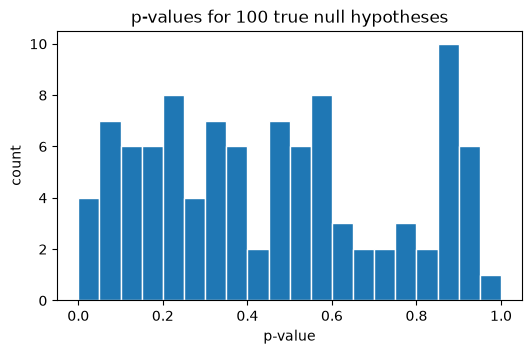

In [6]:
# Exercise 8(a)
rng = np.random.default_rng(1)
n, m = 20, 100
X = rng.normal(size=(n, m))
pvals_8 = ttest_1samp(X, 0).pvalue
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(pvals_8, bins=20, range=(0, 1), edgecolor="white")
ax.set(xlabel="p-value", ylabel="count", title="p-values for 100 true null hypotheses")
plt.show()

### Exercise 8(b)

If we control Type I error for each null hypothesis at level α =
0.05, then how many null hypotheses do we reject?

In [7]:
# Exercise 8(b)
print(f"Rejected at alpha = 0.05 with no adjustment: {(pvals_8 < 0.05).sum()} of {m}")

Rejected at alpha = 0.05 with no adjustment: 4 of 100


### Exercise 8(c)

If we control the FWER at level 0.05, then how many null hypotheses do we reject?

In [8]:
# Exercise 8(c)
print(f"Rejected with FWER controlled at 0.05 (Holm): {multipletests(pvals_8, 0.05, 'holm')[0].sum()}")
print(f"Rejected with FWER controlled at 0.05 (Bonferroni): {multipletests(pvals_8, 0.05, 'bonferroni')[0].sum()}")

Rejected with FWER controlled at 0.05 (Holm): 0
Rejected with FWER controlled at 0.05 (Bonferroni): 0


### Exercise 8(d)

If we control the FDR at level 0.05, then how many null hypotheses do we reject?

In [9]:
# Exercise 8(d)
print(f"Rejected with FDR controlled at 0.05 (BH): {multipletests(pvals_8, 0.05, 'fdr_bh')[0].sum()}")

Rejected with FDR controlled at 0.05 (BH): 0


### Exercise 8(e)

Now suppose we “cherry-pick” the 10 fund managers who perform the best in our data. If we control the FWER for just these
10 fund managers at level 0.05, then how many null hypotheses do we reject? If we control the FDR for just these 10 fund
managers at level 0.05, then how many null hypotheses do we
reject?

In [10]:
# Exercise 8(e)
best10 = np.argsort(X.mean(axis=0))[::-1][:10]        # the 10 managers with the highest average return
p_best = pvals_8[best10]
display(pd.DataFrame({"manager": best10, "mean return": X.mean(axis=0)[best10], "p-value": p_best}).round(4))
print(f"Cherry-picked 10, FWER 0.05 (Holm): {multipletests(p_best, 0.05, 'holm')[0].sum()} rejected")
print(f"Cherry-picked 10, FDR 0.05 (BH):    {multipletests(p_best, 0.05, 'fdr_bh')[0].sum()} rejected")

,manager,mean return,p-value
0,27,0.4867,0.0355
1,44,0.4544,0.0096
2,80,0.3786,0.1380
3,20,0.3735,0.0755
4,11,0.3511,0.1188
5,9,0.3482,0.0780
6,8,0.3295,0.2445
7,56,0.3125,0.2080
8,67,0.3031,0.1535
9,15,0.2879,0.1688


Cherry-picked 10, FWER 0.05 (Holm): 0 rejected
Cherry-picked 10, FDR 0.05 (BH):    0 rejected


### Exercise 8(f)

Explain why the analysis in (e) is misleading.

**Hint:** The standard approaches for controlling the FWER and
FDR assume that all tested null hypotheses are adjusted for multiplicity, and that no “cherry-picking” of the smallest p-values
has occurred. What goes wrong if we cherry-pick?

In [11]:
# Exercise 8(f)
# Simulation: how often does the cherry-picked analysis reject at least one (true) null?
reps = 2000
false_any = {"Holm on all 100": 0, "Holm on top 10": 0, "BH on top 10": 0}
sim_rng = np.random.default_rng(8)
for _ in range(reps):
    Xs = sim_rng.normal(size=(n, m))
    p = ttest_1samp(Xs, 0).pvalue
    top = np.argsort(Xs.mean(axis=0))[::-1][:10]
    false_any["Holm on all 100"] += multipletests(p, 0.05, "holm")[0].any()
    false_any["Holm on top 10"] += multipletests(p[top], 0.05, "holm")[0].any()
    false_any["BH on top 10"] += multipletests(p[top], 0.05, "fdr_bh")[0].any()
pd.Series({k: v / reps for k, v in false_any.items()}, name="P(at least one false rejection)").round(3).to_frame()

,P(at least one false rejection)
Holm on all 100,0.048
Holm on top 10,0.220
BH on top 10,0.250


**Observations / conclusions**

- **(a)** All 100 null hypotheses are true, so the p-values are roughly uniform on [0, 1].
- **(b)** Without adjustment, **4** of the 100 are rejected at α = 0.05. All four are false positives; we expect about 5.
- **(c)** Controlling the FWER at 0.05 (Holm or Bonferroni): **0** rejected.
- **(d)** Controlling the FDR at 0.05 (BH): **0** rejected.
- **(e)** If we cherry-pick the 10 managers with the highest average returns and correct only for those 10, we again get 0 rejections *in this particular sample*. The smallest p-values among the top 10 are 0.0096 and 0.036, so the Holm and BH thresholds just miss them.
- **(f)** The cherry-picked analysis is still misleading. We used the data to choose which 10 hypotheses to test, so those 10 p-values are the smallest of 100 draws, not 10 independent uniform p-values. Bonferroni/Holm and BH assume the correction covers *every* hypothesis that was looked at. In a simulation of 2,000 repetitions, Holm on the top 10 makes at least one false rejection **22%** of the time (BH: 25%), versus the promised 5%. Holm on all 100 achieves 4.8%. Our sample just happened not to produce a false discovery; the procedure does not control the error rate.